# CrossVQA -- Phase B (Task B1): Dataset Re-Exploration, Equivalence Taxonomy & Train-Validation Data Leakage Audit

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/NhanChanDeo/VQA_Final_Thesis/blob/main/DATA_PIPELINE/Assess_data_leakage.ipynb)

> **Thesis Project:** *CrossVQA: Cross-Domain Knowledge Transfer from Document Images to Natural Scene Images for Vision-Language Models*  
> **Phase:** Phase B -- Training Preparation & Data Pipeline Engineering (`DATA_PIPELINE/`)  
> **Target Repositories (`branch: main`):**  
> - **Source Domain (2D Document Scans):** [`gamusa/docvqa-canonical`](https://huggingface.co/datasets/gamusa/docvqa-canonical) (`86e379d727ab104301e3639b909bfbddb0af6376`)  
> - **Target Domain (3D Natural Scenes):** [`gamusa/textvqa-canonical`](https://huggingface.co/datasets/gamusa/textvqa-canonical) (`d1dcf73eda54e82e84f69d0265f3a9e663420583`)  
> **Theoretical & Methodological References:**  
> - Kapoor & Narayanan (2023), *Leakage and the Reproducibility Crisis in Machine Learning-Based Science* (`PLAN/Papers/Dataset_Split_Issue/Kapoor_2023_Data_Leakage.pdf`)  
> - Wang et al. (2024), *Both Text and Images Leaked! A Systematic Analysis of Data Contamination in Multimodal LLM* (`PLAN/Papers/Dataset_Split_Issue/Wang_2024_Both_Text_and_Images_Leaked.pdf`)  
> - Agrawal et al. (2018), *Don't Just Assume; Look and Answer: Overcoming Priors for VQA (VQA-CP)* (`PLAN/Papers/Dataset_Split_Issue/Agrawal_2018_VQA_CP.pdf`)  
> - Li et al. (2024), *LMMs-Eval: Accelerating the Development of Large Multimodal Models* (`PLAN/Papers/Dataset_Split_Issue/Li_2024_LMMs_Eval.pdf`)

---

### Audit Roadmap

Unlike the Phase A exploratory notebooks (`ANALYSIS/`), which profiled a **5,000-row sample per split** (yielding sample-bounded lower-bound estimates), a rigorous data leakage audit requires **100% full-population coverage** across every single training and validation example (**84,414 total rows**). By leveraging columnar Parquet projection (`write_page_index=True`) over the Hugging Face Hub alongside targeted binary hashing, this notebook inspects the **entire benchmark population** in constant memory ($< 500\text{ MB}$ RAM) across four structured stages:

| Stage | Analytical Objective | Core Questions Answered |
| :--- | :--- | :--- |
| **1. Dataset Re-Exploration & Structural Audit** | Inspect live Parquet physical schemas, verify documentation vs. live field definitions, deserialize `metadata` JSON payloads, and map relational entity hierarchies. | What is the exact 15-column schema on `main` vs. `lossless`? How do questions, pages, images, and parent documents relate ($1:M$)? Are there null/malformed records? |
| **2. Defining Entry Equivalence (L0-L5 Taxonomy)** | Formalize what makes two multimodal VQA entries "identical" across identifiers, text-image pairs, visual fingerprints, parent document groups, and text-only priors; audit **intra-split** duplicates. | When are two entries exact duplicates vs. near-duplicate paraphrases vs. shared-entity siblings vs. benign template questions? Do `train` or `validation` contain internal duplicates? |
| **3. Train $\leftrightarrow$ Validation Leakage Audit** | Execute an exact, full-population cross-split overlap audit across all 6 equivalence levels (L0-L5), including content-based OCR/geometry fingerprinting and raw image SHA-256 verification. | Is there any multimodal pair, image, or multi-page document (`ucsf_document_id`) leakage between official `train` and `validation`? What explains the ~3-4% shared question strings flagged in Phase A? |
| **4. Split Protocol Simulation & Phase B Action Plan** | Quantify the leakage induced by naive random splitting (`ShuffleSplit`) vs. `GroupShuffleSplit` when carving out the 5% internal `dev` split from `train` (Task B1). | Why does naive 95/5 splitting leak $>50\%$ of `dev` images/documents into `train`, and why must DocVQA group by `ucsf_document_id` rather than `image_id` alone? |

In [1]:
# 0.1 Environment Configuration, Relative Path Anchor & Accessible Plotting Setup
import gc
import hashlib
import io
import json
import math
import os
import platform
import re
import sys
import time
import warnings
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
from PIL import Image as PILImage
from tqdm.auto import tqdm
from IPython.display import display, Markdown
from huggingface_hub import HfApi, HfFileSystem, hf_hub_url
import datasets
from datasets import load_dataset

warnings.filterwarnings("ignore", category=FutureWarning)
PILImage.MAX_IMAGE_PIXELS = None

# Anchor working directory to the Project Root using strictly relative navigation
if Path.cwd().name == "DATA_PIPELINE":
    os.chdir("..")

REL_PIPELINE_DIR = Path("DATA_PIPELINE")
REL_CACHE_DIR = REL_PIPELINE_DIR / "cache"
REL_FIG_DIR = REL_PIPELINE_DIR / "figures"
REL_REPORT_DIR = REL_PIPELINE_DIR / "reports"
for _d in (REL_CACHE_DIR, REL_FIG_DIR, REL_REPORT_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# Pinned canonical dataset specifications (from PLAN & Step 10 Modernization)
DATASETS_CFG = {
    "docvqa": {
        "repo_id": "gamusa/docvqa-canonical",
        "main_rev": "86e379d727ab104301e3639b909bfbddb0af6376",
        "lossless_rev": "ece7188e9b70ee95d96b69d098c79814fa54cf77",
        "label": "DocVQA",
        "domain_expected": "document_text",
        "color": "#0072B2",   # Okabe-Ito Blue (high-contrast accessible)
        "hatch": "//",
    },
    "textvqa": {
        "repo_id": "gamusa/textvqa-canonical",
        "main_rev": "d1dcf73eda54e82e84f69d0265f3a9e663420583",
        "lossless_rev": "8647985ca5c5fc53163cf5d3c294c5229115a83a",
        "label": "TextVQA",
        "domain_expected": "scene_text",
        "color": "#D55E00",   # Okabe-Ito Vermilion (high-contrast accessible)
        "hatch": "xx",
    },
}

OKABE_ITO = {
    "blue": "#0072B2",
    "vermilion": "#D55E00",
    "green": "#009E73",
    "orange": "#E69F00",
    "sky": "#56B4E9",
    "purple": "#CC79A7",
    "yellow": "#F0E442",
    "grey": "#7F7F7F",
}

plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 150,
    "font.size": 10,
    "axes.titleweight": "bold",
    "axes.labelweight": "bold",
    "axes.titlesize": 11.5,
    "axes.edgecolor": "#222222",
    "axes.linewidth": 1.0,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "legend.frameon": True,
    "legend.framealpha": 0.92,
})

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 180)

SEED = 42
HF_TOKEN = os.environ.get("HF_TOKEN") or None

print(f"Python {sys.version.split()[0]} | Platform: {platform.system()} {platform.release()}")
print(f"pyarrow {pa.__version__} | pandas {pd.__version__} | datasets {datasets.__version__}")
print(f"Relative output dirs ready: {REL_CACHE_DIR.as_posix()}, {REL_FIG_DIR.as_posix()}, {REL_REPORT_DIR.as_posix()}")

Python 3.13.18 | Platform: Linux 6.6.159+
pyarrow 23.0.1 | pandas 2.2.3 | datasets 4.8.5
Relative output dirs ready: DATA_PIPELINE/cache, DATA_PIPELINE/figures, DATA_PIPELINE/reports


# 1. Dataset Re-Exploration & Exact Structural Audit

Before defining duplicate entries or auditing split contamination, we must verify the **ground-truth physical structure** of the published Hugging Face repositories (`gamusa/docvqa-canonical` and `gamusa/textvqa-canonical`) rather than relying solely on project documentation. In particular, we check:
1. **Repository & Branch Topology (`main` vs. `lossless`):** Exact shard counts, split partitions, and storage footprints via the Hugging Face Hub API.
2. **Live PyArrow Physical Schema vs. Documentation:** Reading Parquet file footers directly via HTTP range requests (`HfFileSystem` + `pyarrow.parquet.ParquetFile`) to verify every column name, physical data type, and nested struct definition, reconciling any discrepancies against `README.md` and `DATASETS SCHEMA NORMALIZATION/canonical_schema.py`.
3. **Raw Multimodal Sample & `metadata` JSON Anatomy:** Streaming real samples from both domains to inspect the `image` binary struct (`bytes`, `path`, probed PIL format/mode), OCR grounding arrays (`ocr_tokens`, `ocr_boxes`), answer lists, and domain-specific `metadata` JSON keys.

In [2]:
# 1.1 Repository Branch Topology, Live Parquet Footer Schema & Raw Sample Anatomy
api = HfApi(token=HF_TOKEN)
hf_fs = HfFileSystem(token=HF_TOKEN)

branch_rows = []
live_schemas = {}

for key, cfg in DATASETS_CFG.items():
    for branch_label, rev in [("main (curated)", cfg["main_rev"]), ("lossless (archive)", cfg["lossless_rev"])]:
        info = api.dataset_info(cfg["repo_id"], revision=rev, files_metadata=True)
        parquet_files = [s for s in info.siblings if s.rfilename.endswith(".parquet")]
        split_counts = Counter()
        split_bytes = Counter()
        for pf in parquet_files:
            fname = os.path.basename(pf.rfilename)
            sp = fname.split("-")[0]
            split_counts[sp] += 1
            split_bytes[sp] += (pf.size or 0)
        branch_rows.append({
            "Dataset": cfg["label"],
            "Branch": branch_label,
            "Pinned SHA": info.sha[:12],
            "Total Shards": len(parquet_files),
            "Train Shards": split_counts.get("train", 0),
            "Val Shards": split_counts.get("validation", 0),
            "Test Shards": split_counts.get("test", 0),
            "Size (GB)": round(sum(split_bytes.values()) / (1024 ** 3), 2),
        })
        if "main" in branch_label:
            first_shard = sorted(pf.rfilename for pf in parquet_files)[0]
            with hf_fs.open(f"datasets/{cfg['repo_id']}@{rev}/{first_shard}", "rb") as f_pq:
                pf_reader = pq.ParquetFile(f_pq)
                live_schemas[key] = pf_reader.schema_arrow

display(Markdown("### 1.1a Dual-Branch Repository & Shard Inventory"))
display(pd.DataFrame(branch_rows))

# Compare live PyArrow schema between DocVQA and TextVQA and check against README claims
doc_schema = live_schemas["docvqa"]
txt_schema = live_schemas["textvqa"]
assert doc_schema.equals(txt_schema), "Schema mismatch between DocVQA and TextVQA!"

readme_claimed_cols = {
    "sample_id", "domain_type", "question_id", "question", "image", "image_format",
    "image_width", "image_height", "answers", "canonical_answer", "ocr_tokens",
    "ocr_boxes", "source_dataset", "original_split", "metadata"
}
live_col_names = set(doc_schema.names)

schema_tbl = pd.DataFrame([
    {
        "Idx": i,
        "Column Name": field.name,
        "Live PyArrow Type": str(field.type),
        "In DocVQA & TextVQA?": "Yes (Identical)",
        "Listed in README.md?": "Yes" if field.name in readme_claimed_cols else "NO (Undocumented in README!)",
    }
    for i, field in enumerate(doc_schema)
])
display(Markdown("### 1.1b Exact 15-Column Live PyArrow Schema (Verified from Parquet Footers)"))
display(schema_tbl)
print("Columns claimed in README.md that DO NOT exist in live Parquet shards:",
      sorted(readme_claimed_cols - live_col_names))
print("Columns in live Parquet shards that were OMITTED from README.md:",
      sorted(live_col_names - readme_claimed_cols))

# Stream 1 raw sample per domain to inspect real field values, image struct header, and metadata JSON
sample_previews = []
for key, cfg in DATASETS_CFG.items():
    ds_stream = load_dataset(
        cfg["repo_id"], revision=cfg["main_rev"], split="train", streaming=True, token=HF_TOKEN
    ).cast_column("image", datasets.Image(decode=False))
    row = next(iter(ds_stream))
    raw_bytes = row["image"]["bytes"]
    with PILImage.open(io.BytesIO(raw_bytes)) as im:
        im_fmt, im_mode, im_size = im.format, im.mode, im.size
    meta_dict = json.loads(row["metadata"])
    sample_previews.append({
        "Dataset": cfg["label"],
        "sample_id": row["sample_id"],
        "domain_type": row["domain_type"],
        "split": row["split"],
        "question_id": row["question_id"],
        "image_id": row["image_id"],
        "image.path": row["image"]["path"],
        "PIL (fmt, mode, WxH)": f"{im_fmt}, {im_mode}, {im_size[0]}x{im_size[1]} ({len(raw_bytes)/1024:.1f} KB)",
        "Declared WxH": f"{row['image_width']}x{row['image_height']}",
        "question": row["question"],
        "question_tokens (len)": f"{len(row['question_tokens'])} toks: {row['question_tokens'][:5]}",
        "answers (count)": f"{len(row['answers'])} ans -> canonical='{row['canonical_answer']}'",
        "ocr_tokens / boxes": f"{len(row['ocr_tokens'])} tokens / {len(row['ocr_boxes'])} boxes (e.g. {row['ocr_boxes'][0] if row['ocr_boxes'] else None})",
        "metadata JSON keys": list(meta_dict.keys()),
        "metadata sample": meta_dict,
    })

display(Markdown("### 1.1c Concrete Multimodal Row & `metadata` JSON Inspection"))
display(pd.DataFrame(sample_previews).T)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


### 1.1a Dual-Branch Repository & Shard Inventory

,Dataset,Branch,Pinned SHA,Total Shards,Train Shards,Val Shards,Test Shards,Size (GB)
0,DocVQA,main (curated),86e379d727ab,57,50,7,0,8.35
1,DocVQA,lossless (archive),ece7188e9b70,64,50,7,7,9.46
2,TextVQA,main (curated),d1dcf73eda54,16,14,2,0,6.64
3,TextVQA,lossless (archive),8647985ca5c5,19,14,2,3,7.54


### 1.1b Exact 15-Column Live PyArrow Schema (Verified from Parquet Footers)

,Idx,Column Name,Live PyArrow Type,In DocVQA & TextVQA?,Listed in README.md?
0,0,sample_id,string,Yes (Identical),Yes
1,1,domain_type,string,Yes (Identical),Yes
2,2,split,string,Yes (Identical),NO (Undocumented in README!)
3,3,question_id,string,Yes (Identical),Yes
4,4,question,string,Yes (Identical),Yes
5,5,question_tokens,list<element: string>,Yes (Identical),NO (Undocumented in README!)
6,6,image_id,string,Yes (Identical),NO (Undocumented in README!)
7,7,image,"struct<bytes: binary, path: string>",Yes (Identical),Yes
8,8,image_width,int64,Yes (Identical),Yes
9,9,image_height,int64,Yes (Identical),Yes


Columns claimed in README.md that DO NOT exist in live Parquet shards: ['image_format', 'original_split', 'source_dataset']
Columns in live Parquet shards that were OMITTED from README.md: ['image_id', 'question_tokens', 'split']


... (2 outputs left out)

Resolving data files:   0%|          | 0/50 [00:00<?, ?it/s]

README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

### 1.1c Concrete Multimodal Row & `metadata` JSON Inspection

,0,1
Dataset,DocVQA,TextVQA
sample_id,docvqa_337,textvqa_0
domain_type,document_text,scene_text
split,train,train
question_id,337,0
image_id,xnbl0037_1.png,0054c91397f2fe05
image.path,xnbl0037_1.png,0054c91397f2fe05.jpg
"PIL (fmt, mode, WxH)","PNG, L, 1695x2025 (56.2 KB)","JPEG, RGB, 1024x730 (454.0 KB)"
Declared WxH,1695x2025,1024x730
question,what is the date mentioned in this letter?,what is the brand of phone?


**Structural Discovery & Schema Reconciliation (Section 1.1 Analysis):**

Re-exploring the live Hugging Face Parquet shards surfaces three critical structural facts that directly govern how entry identity and split leakage must be computed:

1. **Documentation Drift Reconciled (`README.md` vs. Live Parquet Footers):**
   - Both `gamusa/docvqa-canonical` (57 shards on `main`, 8.35 GB) and `gamusa/textvqa-canonical` (16 shards on `main`, 6.64 GB) share an **identical 15-column PyArrow schema**, and the blind `test` split (7 shards in DocVQA, 3 shards in TextVQA on `lossless`) is confirmed **100% pruned on `main`**.
   - However, inspecting the live Parquet footers reveals that three columns listed in `README.md` -- `image_format`, `original_split`, and `source_dataset` -- **do not exist** in the physical Parquet schema. Instead, the live shards store `split` (`string`), `question_tokens` (`list<string>`), and `image_id` (`string`), while image encoding format (`PNG` vs. `JPEG`) lives implicitly inside the raw byte header of `image.bytes` (`struct<bytes: binary, path: string>`). Any pipeline or leakage script referencing the `README.md` field names would raise a `KeyError`.

2. **Asymmetric Entity Identifiers Across Domains:**
   - **DocVQA (`document_text`):** `image_id` includes the file extension and encodes both document and page (`"xnbl0037_1.png"`, matching `image.path`), while `metadata` deserializes into **4 domain keys**: `question_types` (`list<str>`), `docId` (`int`), `ucsf_document_id` (`str`, e.g., `"xnbl0037"`), and `ucsf_document_page_no` (`str`, e.g., `"1"`). Thus, DocVQA has a **multi-tier document-to-page-to-question hierarchy**.
   - **TextVQA (`scene_text`):** `image_id` is a 16-character OpenImages hex hash *without* extension (`"0054c91397f2fe05"`, whereas `image.path` is `"0054c91397f2fe05.jpg"`), and `metadata` deserializes into **3 domain keys**: `image_classes` (`list<str>`), `flickr_original_url` (`str`), and `exif_transposed` (`bool`).

3. **Columnar Projection Enables Exact Full-Population Auditing:**
   - Because `image` (`struct<bytes, path>`) is physically isolated in separate Parquet column chunks from the 14 scalar/list/JSON columns, we can project all 14 non-image columns across **all 73 shards (all 84,414 rows)** in seconds, and selectively fetch `image.bytes` only when verifying visual hash collisions.

---

### 1.2 Full-Population Columnar Ingestion, Completeness & Entity Hierarchy Profiling

Next, we ingest **100% of `train` and `validation` rows** across both repositories (all **44,812** DocVQA entries and all **39,602** TextVQA entries), check every column for null/empty/malformed values, and quantify the exact $1:M$ entity multiplicity (questions per image, pages per parent document, questions per parent document).

In [3]:
# 1.2 Full-Population Columnar Ingestion (All 84,414 Rows) & Relational Hierarchy Audit
NON_IMAGE_COLS = [
    "sample_id", "domain_type", "split", "question_id", "question",
    "question_tokens", "image_id", "image_width", "image_height",
    "answers", "canonical_answer", "ocr_tokens", "ocr_boxes", "metadata",
]

_PUNCT_RE = re.compile(r"[^\w\s]")
_ARTICLES_RE = re.compile(r"\b(a|an|the)\b")
_WS_RE = re.compile(r"\s+")

def norm_vqa_text(s: str | None, drop_articles: bool = False) -> str:
    if s is None:
        return ""
    out = _PUNCT_RE.sub(" ", str(s).lower())
    if drop_articles:
        out = _ARTICLES_RE.sub(" ", out)
    return _WS_RE.sub(" ", out).strip()

def _read_single_shard(repo_id: str, rev: str, rfilename: str) -> pd.DataFrame:
    local_fs = HfFileSystem(token=HF_TOKEN)
    uri = f"datasets/{repo_id}@{rev}/{rfilename}"
    with local_fs.open(uri, "rb") as f_pq:
        tbl = pq.read_table(f_pq, columns=NON_IMAGE_COLS)
    cols = tbl.to_pydict()
    n = tbl.num_rows
    shard_base = os.path.basename(rfilename)
    split_from_file = shard_base.split("-")[0]

    records = []
    for idx in range(n):
        q_raw = cols["question"][idx] or ""
        q_norm = norm_vqa_text(q_raw, drop_articles=False)
        q_sem = norm_vqa_text(q_raw, drop_articles=True)
        q_toks = cols["question_tokens"][idx]
        q_bag = " ".join(sorted(q_sem.split()))

        ans_list = cols["answers"][idx]
        ans_Null = ans_list is None
        ans_list = list(ans_list) if ans_list is not None else []
        canon = cols["canonical_answer"][idx]
        canon_norm = norm_vqa_text(canon, drop_articles=False)
        ans_norm_clean = [norm_vqa_text(a) for a in ans_list if norm_vqa_text(a)]
        ans_exact_sig = hashlib.sha1("\x1f".join(ans_list).encode("utf-8")).hexdigest()[:16]
        ans_set_sig = "|".join(sorted(set(ans_norm_clean)))

        ocr_toks = cols["ocr_tokens"][idx]
        ocr_bxs = cols["ocr_boxes"][idx]
        ocr_toks_l = list(ocr_toks) if ocr_toks is not None else []
        ocr_bxs_l = list(ocr_bxs) if ocr_bxs is not None else []
        w = cols["image_width"][idx]
        h = cols["image_height"][idx]

        # Deterministic visual-OCR geometry signature + normalized OCR text signature
        ocr_geom_payload = f"{w}x{h}||" + "\x1f".join(ocr_toks_l) + "||" + ";".join(
            ",".join(map(str, b)) for b in ocr_bxs_l if b is not None
        )
        ocr_geom_sha1 = hashlib.sha1(ocr_geom_payload.encode("utf-8")).hexdigest()[:16]
        ocr_norm_toks = [norm_vqa_text(t) for t in ocr_toks_l if norm_vqa_text(t)]
        ocr_text_sha1 = hashlib.sha1(" ".join(ocr_norm_toks).encode("utf-8")).hexdigest()[:16] if ocr_norm_toks else "EMPTY_OCR"

        meta_str = cols["metadata"][idx]
        meta_err = False
        try:
            meta = json.loads(meta_str) if meta_str else {}
        except Exception:
            meta = {}
            meta_err = True

        rec = {
            "shard_file": shard_base,
            "row_in_shard": idx,
            "split_file": split_from_file,
            "sample_id": cols["sample_id"][idx],
            "domain_type": cols["domain_type"][idx],
            "split": cols["split"][idx],
            "question_id": cols["question_id"][idx],
            "image_id": cols["image_id"][idx],
            "image_width": w,
            "image_height": h,
            "question": q_raw,
            "question_norm": q_norm,
            "question_sem": q_sem,
            "question_bag": q_bag,
            "question_tok_len": len(q_toks) if q_toks is not None else -1,
            "canonical_answer": canon,
            "answer_norm": canon_norm,
            "answers_count": len(ans_list),
            "answers_null": ans_Null,
            "answers_exact_sig": ans_exact_sig,
            "answers_norm_set": ans_set_sig,
            "ocr_token_count": len(ocr_toks_l),
            "ocr_box_count": len(ocr_bxs_l),
            "ocr_geom_sha1": ocr_geom_sha1,
            "ocr_text_sha1": ocr_text_sha1,
            "meta_parse_error": meta_err,
            # Domain-specific metadata fields (populated when present)
            "docId": str(meta["docId"]) if "docId" in meta and meta["docId"] is not None else None,
            "ucsf_document_id": meta.get("ucsf_document_id") or None,
            "ucsf_document_page_no": str(meta["ucsf_document_page_no"]) if "ucsf_document_page_no" in meta and meta["ucsf_document_page_no"] is not None else None,
            "question_types": "|".join(sorted(meta.get("question_types") or [])) if "question_types" in meta else None,
            "flickr_original_url": (meta.get("flickr_original_url") or "").strip() or None,
            "exif_transposed": meta.get("exif_transposed") if "exif_transposed" in meta else None,
            "image_classes_count": len(meta.get("image_classes") or []) if "image_classes" in meta else None,
        }
        records.append(rec)
    return pd.DataFrame(records)

def load_full_dataset_index(key: str, force_refresh: bool = False) -> pd.DataFrame:
    cache_file = REL_CACHE_DIR / f"{key}_leakage_index.parquet"
    if cache_file.exists() and not force_refresh:
        df = pd.read_parquet(cache_file)
        print(f"[cache hit] Loaded {len(df):,} rows from {cache_file.as_posix()}")
        return df

    cfg = DATASETS_CFG[key]
    t0 = time.time()
    info = api.dataset_info(cfg["repo_id"], revision=cfg["main_rev"], files_metadata=False)
    shard_paths = sorted(s.rfilename for s in info.siblings if s.rfilename.endswith(".parquet"))
    print(f"Streaming {len(shard_paths)} shards from {cfg['repo_id']}@{cfg['main_rev'][:10]} (columnar non-image projection)...")

    parts = []
    with ThreadPoolExecutor(max_workers=8) as pool:
        futs = {pool.submit(_read_single_shard, cfg["repo_id"], cfg["main_rev"], sp): sp for sp in shard_paths}
        for fut in tqdm(as_completed(futs), total=len(futs), desc=f"{cfg['label']} shards"):
            parts.append(fut.result())

    df = pd.concat(parts, ignore_index=True).sort_values(["split", "shard_file", "row_in_shard"]).reset_index(drop=True)
    df.to_parquet(cache_file, index=False, compression="zstd")
    print(f"[saved] {cache_file.as_posix()} | {len(df):,} rows in {time.time() - t0:.1f}s | RAM: {df.memory_usage(deep=True).sum()/(1024**2):.1f} MB")
    return df

df_doc = load_full_dataset_index("docvqa")
df_txt = load_full_dataset_index("textvqa")

# 1.2a Full-population completeness & structural integrity summary
integrity_summary = []
for key, df in [("DocVQA", df_doc), ("TextVQA", df_txt)]:
    for sp, g in df.groupby("split", sort=False):
        integrity_summary.append({
            "Dataset": key,
            "Split": sp,
            "Total Rows": len(g),
            "Shard Mismatch (split!=file)": int((g["split"] != g["split_file"]).sum()),
            "Null Core Fields": int(g[["sample_id", "question_id", "question", "image_id", "canonical_answer"]].isna().any(axis=1).sum()),
            "Empty Questions": int((g["question_norm"] == "").sum()),
            "Empty Answers (len==0)": int((g["answers_count"] == 0).sum()),
            "OCR Token!=Box Mismatch": int((g["ocr_token_count"] != g["ocr_box_count"]).sum()),
            "Zero-OCR Rows": f"{int((g['ocr_token_count'] == 0).sum())} ({(g['ocr_token_count'] == 0).mean():.2%})",
            "Unique sample_id": g["sample_id"].nunique(),
            "Unique question_id": g["question_id"].nunique(),
            "Unique image_id": g["image_id"].nunique(),
            "Unique Parent Docs (ucsf_doc_id)": g["ucsf_document_id"].nunique() if key == "DocVQA" else "N/A (Flat)",
            "Mean Qs / Image": round(len(g) / g["image_id"].nunique(), 2),
            "Mean Pages / Doc": round(g.groupby("ucsf_document_id")["image_id"].nunique().mean(), 2) if key == "DocVQA" else "N/A",
            "Mean Qs / Doc": round(len(g) / g["ucsf_document_id"].nunique(), 2) if key == "DocVQA" else "N/A",
        })

display(Markdown("### 1.2a Full-Population Structural Completeness & Entity Cardinality (84,414 Rows)"))
display(pd.DataFrame(integrity_summary))

# 1.2b Detailed multiplicity quantiles (why group dependence matters)
mult_rows = []
# DocVQA: questions per page (image_id), pages per ucsf_document_id, questions per ucsf_document_id
for label, s in [
    ("DocVQA: Questions per Page (image_id)", df_doc.groupby("image_id").size()),
    ("DocVQA: Pages per Document (ucsf_document_id)", df_doc.groupby("ucsf_document_id")["image_id"].nunique()),
    ("DocVQA: Questions per Document (ucsf_document_id)", df_doc.groupby("ucsf_document_id").size()),
    ("TextVQA: Questions per Scene Image (image_id)", df_txt.groupby("image_id").size()),
]:
    mult_rows.append({
        "Entity Relationship": label,
        "Distinct Parent Entities": len(s),
        "Min": int(s.min()),
        "Median (p50)": float(s.median()),
        "Mean": round(float(s.mean()), 2),
        "p90": float(s.quantile(0.90)),
        "p99": float(s.quantile(0.99)),
        "Max": int(s.max()),
        "Entities with >=2 Children (%)": f"{(s >= 2).mean():.2%}",
    })

display(Markdown("### 1.2b Relational Multiplicity Distributions ($1:M$ Group Structure)"))
display(pd.DataFrame(mult_rows))

Streaming 57 shards from gamusa/docvqa-canonical@86e379d727 (columnar non-image projection)...


DocVQA shards:   0%|          | 0/57 [00:00<?, ?it/s]

[saved] DATA_PIPELINE/cache/docvqa_leakage_index.parquet | 44,812 rows in 354.5s | RAM: 64.8 MB
Streaming 16 shards from gamusa/textvqa-canonical@d1dcf73eda (columnar non-image projection)...


TextVQA shards:   0%|          | 0/16 [00:00<?, ?it/s]

[saved] DATA_PIPELINE/cache/textvqa_leakage_index.parquet | 39,602 rows in 202.9s | RAM: 53.5 MB


### 1.2a Full-Population Structural Completeness & Entity Cardinality (84,414 Rows)

,Dataset,Split,Total Rows,Shard Mismatch (split!=file),Null Core Fields,Empty Questions,Empty Answers (len==0),OCR Token!=Box Mismatch,Zero-OCR Rows,Unique sample_id,Unique question_id,Unique image_id,Unique Parent Docs (ucsf_doc_id),Mean Qs / Image,Mean Pages / Doc,Mean Qs / Doc
0,DocVQA,train,39463,0,0,0,0,0,4 (0.01%),39463,39463,10194,5272,3.87,1.93,7.49
1,DocVQA,validation,5349,0,0,0,0,0,0 (0.00%),5349,5349,1286,938,4.16,1.37,5.7
2,TextVQA,train,34602,0,0,0,0,0,876 (2.53%),34602,34602,21953,N/A (Flat),1.58,N/A,N/A
3,TextVQA,validation,5000,0,0,0,0,0,115 (2.30%),5000,5000,3166,N/A (Flat),1.58,N/A,N/A


### 1.2b Relational Multiplicity Distributions ($1:M$ Group Structure)

,Entity Relationship,Distinct Parent Entities,Min,Median (p50),Mean,p90,p99,Max,Entities with >=2 Children (%)
0,DocVQA: Questions per Page (image_id),11480,1,3.0,3.90,8.0,10.00,13,83.11%
1,DocVQA: Pages per Document (ucsf_document_id),5687,1,1.0,2.02,4.0,15.00,140,31.69%
2,DocVQA: Questions per Document (ucsf_document_id),5687,1,5.0,7.88,15.0,57.14,762,89.85%
3,TextVQA: Questions per Scene Image (image_id),25119,1,2.0,1.58,2.0,2.00,2,57.66%


### 1.3 Relational Multiplicity Visualizations & Co-Occurring Question Exemplars

The quantiles established in **Table 1.2b** proved that entries in both DocVQA and TextVQA strongly violate the standard independent-and-identically-distributed (i.i.d.) assumption due to hierarchical grouping:
1. **Questions per Image (`image_id`):**
   - In **DocVQA**, 83.11% of scanned pages have $\ge 2$ questions (mean = 3.90, max = 13), reflecting dense document regions where annotators probed multiple fields (dates, totals, headers, signatures).
   - In **TextVQA**, 57.66% of scene images have 2 questions (mean = 1.58, max = 2), capturing distinct scene text instances in the physical scene.
2. **Multi-Page Hierarchy (`ucsf_document_id`):**
   - In **DocVQA**, 31.69% of documents span multiple pages (up to 140 pages, mean = 2.02 pages/doc), with questions spread across pages (mean = 7.49 Qs/doc, max = 762 Qs/doc).
   - Splitting solely on `image_id` leaks multi-page document styling, letterheads, and institutional context.

Below, we visualize these three structural distributions side-by-side using Okabe-Ito accessible palettes and inspect concrete qualitative exemplars of co-occurring questions sharing identical visual inputs.

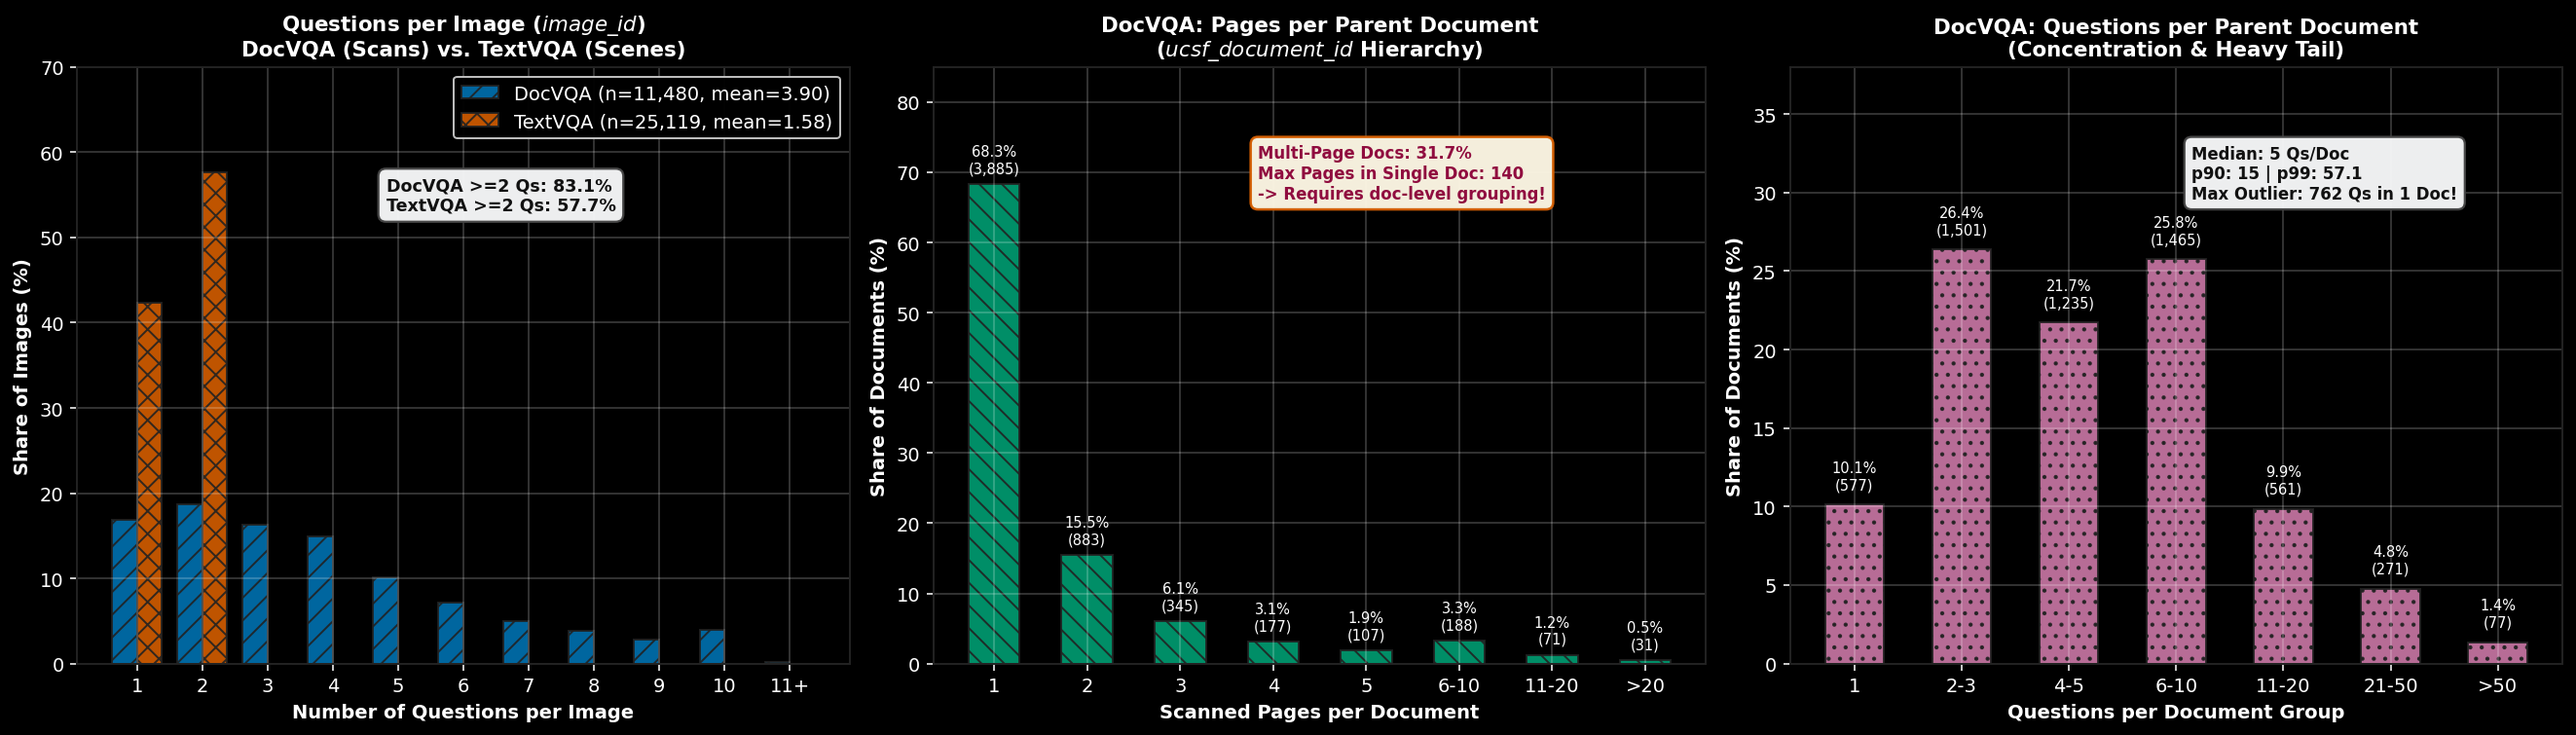

[saved] Multiplicity distribution figure: DATA_PIPELINE/figures/stage1_relational_multiplicity_distributions.png


In [9]:
# 1.3a Visualizing Relational Multiplicity Distributions
# Evaluates Questions/Image across domains, Pages/Doc in DocVQA, and Questions/Doc concentration

s_doc_img = df_doc.groupby("image_id").size()
s_doc_pages = df_doc.groupby("ucsf_document_id")["image_id"].nunique()
s_doc_qs = df_doc.groupby("ucsf_document_id").size()
s_txt_img = df_txt.groupby("image_id").size()

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), dpi=140)

# Explicit high-contrast callout boxes: solid light fill with explicit dark text (#111111)
# This ensures perfect readability in BOTH light mode and dark mode IDE themes.
BOX_KW_LIGHT = dict(boxstyle="round,pad=0.45", fc="#F8F9FA", ec="#444444", lw=1.2, alpha=0.96)
BOX_KW_WARN  = dict(boxstyle="round,pad=0.45", fc="#FFF9E6", ec="#D55E00", lw=1.3, alpha=0.96)

# --- Subplot 1: Questions per Image (DocVQA vs TextVQA) ---
ax1 = axes[0]
bins_img = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
doc_counts = [int((s_doc_img == k).sum()) for k in bins_img] + [int((s_doc_img >= 11).sum())]
txt_counts = [int((s_txt_img == k).sum()) for k in bins_img] + [int((s_txt_img >= 11).sum())]

doc_pcts = [c / len(s_doc_img) * 100 for c in doc_counts]
txt_pcts = [c / len(s_txt_img) * 100 for c in txt_counts]

x_labels = [str(k) for k in bins_img] + ["11+"]
x = np.arange(len(x_labels))
w = 0.38

b1 = ax1.bar(x - w/2, doc_pcts, width=w, label=f"DocVQA (n={len(s_doc_img):,}, mean={s_doc_img.mean():.2f})",
             color=DATASETS_CFG["docvqa"]["color"], edgecolor="#222222", hatch=DATASETS_CFG["docvqa"]["hatch"], alpha=0.9)
b2 = ax1.bar(x + w/2, txt_pcts, width=w, label=f"TextVQA (n={len(s_txt_img):,}, mean={s_txt_img.mean():.2f})",
             color=DATASETS_CFG["textvqa"]["color"], edgecolor="#222222", hatch=DATASETS_CFG["textvqa"]["hatch"], alpha=0.9)

ax1.set_title("Questions per Image ($image\\_id$)\nDocVQA (Scans) vs. TextVQA (Scenes)", fontsize=11, fontweight="bold")
ax1.set_xlabel("Number of Questions per Image", fontweight="bold")
ax1.set_ylabel("Share of Images (%)", fontweight="bold")
ax1.set_xticks(x)
ax1.set_xticklabels(x_labels)
ax1.set_ylim(0, 70)
ax1.legend(loc="upper right", framealpha=0.95)
# Repositioned to center-right empty space (x >= 3) with explicit dark text to eliminate bar collision & dark-mode wash-out
ax1.annotate(f"DocVQA >=2 Qs: {(s_doc_img >= 2).mean():.1%}\nTextVQA >=2 Qs: {(s_txt_img >= 2).mean():.1%}",
             xy=(0.40, 0.76), xycoords="axes fraction",
             color="#111111", bbox=BOX_KW_LIGHT,
             fontsize=9, fontweight="bold")

# --- Subplot 2: DocVQA Pages per Document ---
ax2 = axes[1]
page_bins = [1, 2, 3, 4, 5]
doc_page_counts = [int((s_doc_pages == k).sum()) for k in page_bins]
doc_page_counts.append(int(((s_doc_pages >= 6) & (s_doc_pages <= 10)).sum()))
doc_page_counts.append(int(((s_doc_pages >= 11) & (s_doc_pages <= 20)).sum()))
doc_page_counts.append(int((s_doc_pages > 20).sum()))

page_pcts = [c / len(s_doc_pages) * 100 for c in doc_page_counts]
page_labels = ["1", "2", "3", "4", "5", "6-10", "11-20", ">20"]
x2 = np.arange(len(page_labels))

b_p = ax2.bar(x2, page_pcts, width=0.55, color=OKABE_ITO["green"], edgecolor="#222222", hatch="\\\\", alpha=0.9)
ax2.set_title("DocVQA: Pages per Parent Document\n($ucsf\\_document\\_id$ Hierarchy)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Scanned Pages per Document", fontweight="bold")
ax2.set_ylabel("Share of Documents (%)", fontweight="bold")
ax2.set_xticks(x2)
ax2.set_xticklabels(page_labels)
ax2.set_ylim(0, 85)

for bar, count in zip(b_p, doc_page_counts):
    h_val = bar.get_height()
    if h_val > 0.5:
        ax2.annotate(f"{h_val:.1f}%\n({count:,})",
                     xy=(bar.get_x() + bar.get_width() / 2, h_val + 1.2),
                     xytext=(0, 0), textcoords="offset points",
                     ha="center", va="bottom", fontsize=7.5)

ax2.annotate(f"Multi-Page Docs: {(s_doc_pages >= 2).mean():.1%}\nMax Pages in Single Doc: {s_doc_pages.max()}\n-> Requires doc-level grouping!",
             xy=(0.42, 0.78), xycoords="axes fraction",
             color="#900C3F", bbox=BOX_KW_WARN,
             fontsize=8.5, fontweight="bold")

# --- Subplot 3: DocVQA Questions per Parent Document ---
ax3 = axes[2]
q_bins_labels = ["1", "2-3", "4-5", "6-10", "11-20", "21-50", ">50"]
q_counts = [
    int((s_doc_qs == 1).sum()),
    int(((s_doc_qs >= 2) & (s_doc_qs <= 3)).sum()),
    int(((s_doc_qs >= 4) & (s_doc_qs <= 5)).sum()),
    int(((s_doc_qs >= 6) & (s_doc_qs <= 10)).sum()),
    int(((s_doc_qs >= 11) & (s_doc_qs <= 20)).sum()),
    int(((s_doc_qs >= 21) & (s_doc_qs <= 50)).sum()),
    int((s_doc_qs > 50).sum()),
]
q_pcts = [c / len(s_doc_qs) * 100 for c in q_counts]
x3 = np.arange(len(q_bins_labels))

b_q = ax3.bar(x3, q_pcts, width=0.55, color=OKABE_ITO["purple"], edgecolor="#222222", hatch="..", alpha=0.9)
ax3.set_title("DocVQA: Questions per Parent Document\n(Concentration & Heavy Tail)", fontsize=11, fontweight="bold")
ax3.set_xlabel("Questions per Document Group", fontweight="bold")
ax3.set_ylabel("Share of Documents (%)", fontweight="bold")
ax3.set_xticks(x3)
ax3.set_xticklabels(q_bins_labels)
ax3.set_ylim(0, 38)

for bar, count in zip(b_q, q_counts):
    h_val = bar.get_height()
    if h_val > 0.5:
        ax3.annotate(f"{h_val:.1f}%\n({count:,})",
                     xy=(bar.get_x() + bar.get_width() / 2, h_val + 0.8),
                     xytext=(0, 0), textcoords="offset points",
                     ha="center", va="bottom", fontsize=7.5)

# Repositioned to empty area on the right (x >= 4) with explicit dark text to avoid peak collision
ax3.annotate(f"Median: {s_doc_qs.median():.0f} Qs/Doc\np90: {s_doc_qs.quantile(0.90):.0f} | p99: {s_doc_qs.quantile(0.99):.1f}\nMax Outlier: {s_doc_qs.max()} Qs in 1 Doc!",
             xy=(0.52, 0.78), xycoords="axes fraction",
             color="#111111", bbox=BOX_KW_LIGHT,
             fontsize=8.5, fontweight="bold")

plt.tight_layout()
fig_path = REL_FIG_DIR / "stage1_relational_multiplicity_distributions.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"[saved] Multiplicity distribution figure: {fig_path.as_posix()}")


In [5]:
# 1.3b Co-Occurring Question Exemplars (Identical Visual Input, Distinct Questions)

def display_page_exemplar(df: pd.DataFrame, image_id: str, title: str):
    sub = df[df["image_id"] == image_id].sort_values("question_id").reset_index(drop=True)
    meta = sub.iloc[0]
    md = [
        f"#### {title}",
        f"- **Dataset & Split:** `{meta['domain_type']}` (`{meta['split']}`)",
        f"- **Image ID (`image_id`):** `{image_id}` ({meta['image_width']} x {meta['image_height']} px)",
        f"- **Parent Document ID (`ucsf_document_id`):** `{meta.get('ucsf_document_id', 'N/A')}` (Page {meta.get('ucsf_document_page_no', '1')})",
        f"- **Total Co-Occurring Questions on This Page:** **{len(sub)}**",
        "",
        "| # | Question ID | Question Text | Canonical Answer | OCR Tokens Count |",
        "| :---: | :---: | :--- | :--- | :---: |",
    ]
    for idx, row in sub.iterrows():
        md.append(f"| {idx+1} | `{row['question_id']}` | {row['question']} | **`{row['canonical_answer']}`** | {row['ocr_token_count']} |")
    display(Markdown("\n".join(md)))

def display_multipage_doc_exemplar(df: pd.DataFrame, ucsf_doc_id: str):
    sub = df[df["ucsf_document_id"] == ucsf_doc_id].sort_values(["ucsf_document_page_no", "question_id"]).reset_index(drop=True)
    pages = sorted(sub["image_id"].unique())
    md = [
        f"#### DocVQA Multi-Page Document Spread (`ucsf_document_id = {ucsf_doc_id}`)",
        f"- **Parent Document ID:** `{ucsf_doc_id}` (Split: `{sub.iloc[0]['split']}`)",
        f"- **Total Scanned Pages:** **{len(pages)}** (`{', '.join(pages)}`)",
        f"- **Total Questions Across Pages:** **{len(sub)}**",
        "",
        "> [!WARNING]",
        "> **Why `image_id` grouping alone fails:** If `ffdh0227_1.png` is assigned to `train` and `ffdh0227_3.png` to `dev`, the model has already memorized the document's header, typography, letterhead, and author, causing **cross-page context contamination**.",
        "",
        "| Page No. | Image ID | Question ID | Question Text | Canonical Answer |",
        "| :---: | :---: | :---: | :--- | :--- |",
    ]
    for _, row in sub.iterrows():
        md.append(f"| Page {row['ucsf_document_page_no']} | `{row['image_id']}` | `{row['question_id']}` | {row['question']} | **`{row['canonical_answer']}`** |")
    display(Markdown("\n".join(md)))

def display_textvqa_exemplar(df: pd.DataFrame):
    img_counts = df["image_id"].value_counts()
    multi_imgs = img_counts[img_counts >= 2].index
    if len(multi_imgs) == 0:
        return
    img_id = multi_imgs[0]
    sub = df[df["image_id"] == img_id].sort_values("question_id").reset_index(drop=True)
    meta = sub.iloc[0]
    md = [
        f"#### TextVQA Natural Scene Image with Co-Occurring Questions (`image_id = {img_id}`)",
        f"- **Dataset & Split:** TextVQA (`{meta['split']}`)",
        f"- **Image ID:** `{img_id}` ({meta['image_width']} x {meta['image_height']} px)",
        f"- **Questions Co-Occurring on Scene:** **{len(sub)}** independent questions",
        "",
        "| # | Question ID | Question Text | Canonical Answer |",
        "| :---: | :---: | :--- | :--- |",
    ]
    for idx, row in sub.iterrows():
        md.append(f"| {idx+1} | `{row['question_id']}` | {row['question']} | **`{row['canonical_answer']}`** |")
    display(Markdown("\n".join(md)))

display(Markdown("### 1.3b Co-Occurring Question Exemplars"))

# Exemplar 1: High-density single page in DocVQA (12 questions on one scan)
display_page_exemplar(df_doc, "ntbf0004_1.png", "Exemplar 1 (DocVQA): Dense Single-Page Queries (12 Questions on 1 Scan)")

# Exemplar 2: Multi-page document spread in DocVQA (15 questions across 3 pages)
display_multipage_doc_exemplar(df_doc, "ffdh0227")

# Exemplar 3: TextVQA scene image with multiple questions
display_textvqa_exemplar(df_txt)


### 1.3b Co-Occurring Question Exemplars

#### Exemplar 1 (DocVQA): Dense Single-Page Queries (12 Questions on 1 Scan)
- **Dataset & Split:** `document_text` (`train`)
- **Image ID (`image_id`):** `ntbf0004_1.png` (1692 x 2245 px)
- **Parent Document ID (`ucsf_document_id`):** `ntbf0004` (Page 1)
- **Total Co-Occurring Questions on This Page:** **12**

| # | Question ID | Question Text | Canonical Answer | OCR Tokens Count |
| :---: | :---: | :--- | :--- | :---: |
| 1 | `52735` | What type of "Form" is this? | **`Response Code Request Form`** | 162 |
| 2 | `52736` | What is the "Fax" number mentioned in the form? | **`(910) 741-1672`** | 162 |
| 3 | `52738` | What is RJR Brand? | **`CAMEL`** | 162 |
| 4 | `52740` | What is the "RJR Program #" number given? | **`600368`** | 162 |
| 5 | `52747` | What is the "Response Code" mentioned in the form? | **`U80`** | 162 |
| 6 | `52748` | What is the "Project Name"? | **`1996 Camel Pool Personal Sell Events`** | 162 |
| 7 | `53089` | What is the "Quantity" mentioned under "Distribution:"? | **`5,000`** | 162 |
| 8 | `53093` | What is the "Offer Complete" date mentioned under "Timing:"? | **`12/31/96`** | 162 |
| 9 | `53096` | Who is the "Marketing Person Responsible for Project"? | **`Dennis Dillard`** | 162 |
| 10 | `53101` | Who is the "Production Contact"? | **`Cynthia Stevens`** | 162 |
| 11 | `53108` | Response Code is requested by whom? | **`Lisa Drum`** | 162 |
| 12 | `53110` | What is the "Agency Name"? | **`Print shop job`** | 162 |

#### DocVQA Multi-Page Document Spread (`ucsf_document_id = ffdh0227`)
- **Parent Document ID:** `ffdh0227` (Split: `train`)
- **Total Scanned Pages:** **3** (`ffdh0227_1.png, ffdh0227_3.png, ffdh0227_4.png`)
- **Total Questions Across Pages:** **15**

> [!WARNING]
> **Why `image_id` grouping alone fails:** If `ffdh0227_1.png` is assigned to `train` and `ffdh0227_3.png` to `dev`, the model has already memorized the document's header, typography, letterhead, and author, causing **cross-page context contamination**.

| Page No. | Image ID | Question ID | Question Text | Canonical Answer |
| :---: | :---: | :---: | :--- | :--- |
| Page 1 | `ffdh0227_1.png` | `28561` | what is the notification about? | **`NOTIFICATION OF PERSONNEL ACTION`** |
| Page 1 | `ffdh0227_1.png` | `28563` | what is written at bottom of page? | **`1. EMPLOYEE COPY`** |
| Page 1 | `ffdh0227_1.png` | `28566` | who is the chief of Personnel, NIH ? | **`JOHN M. SANGSTER`** |
| Page 1 | `ffdh0227_1.png` | `28569` | what is pay plan and Occupation code ? | **`EC-0602`** |
| Page 1 | `ffdh0227_1.png` | `28573` | what is the date on which the document is signed ? | **`05-01-67`** |
| Page 3 | `ffdh0227_3.png` | `28855` | What is the document title? | **`confidential statement of employment and financial interests`** |
| Page 3 | `ffdh0227_3.png` | `28856` | What is the name given? | **`Shank, Robert E.`** |
| Page 3 | `ffdh0227_3.png` | `28858` | Where is the location of NIH Nutrition Study Section? | **`Bethesda, Md.`** |
| Page 3 | `ffdh0227_3.png` | `28859` | What is the EST. NO. OF DAYS corresponding to Population Growth and Food Needs? | **`8`** |
| Page 3 | `ffdh0227_3.png` | `28860` | What is the title or kind of position in State of California Dept. of Public Health? | **`Nutrition Consultant`** |
| Page 4 | `ffdh0227_4.png` | `28451` | What  is the name of organization given in the document? | **`RAISTON-PURINA CO.`** |
| Page 4 | `ffdh0227_4.png` | `28452` | What is the kind of Organization mentioned in the document? | **`MANUFACTURING`** |
| Page 4 | `ffdh0227_4.png` | `28453` | What is the social security number given in the document? | **`499-34-0397`** |
| Page 4 | `ffdh0227_4.png` | `28454` | What is the date signed as per the document? | **`FEB. 10, 1967`** |
| Page 4 | `ffdh0227_4.png` | `28455` | What is the nature of interest and in whose name it is held? | **`STOCKHOLDER - 200 SHARES (R.E. & E.C. SHANK)`** |

#### TextVQA Natural Scene Image with Co-Occurring Questions (`image_id = ff9b80a751bc3ecc`)
- **Dataset & Split:** TextVQA (`validation`)
- **Image ID:** `ff9b80a751bc3ecc` (1024 x 1024 px)
- **Questions Co-Occurring on Scene:** **2** independent questions

| # | Question ID | Question Text | Canonical Answer |
| :---: | :---: | :--- | :--- |
| 1 | `39600` | how many points does ga state have? | **`58`** |
| 2 | `39601` | when is this being aired? | **`unanswerable`** |

---

### 1.4 Z-Score Outlier Investigation ($z \in [-3, +3]$ Inlier Region vs. $|z| > 3$ Outliers)

To quantify the severity of the right-tail skew observed in Section 1.2 and Section 1.3, we formally define statistical inliers and outliers using the standard **$z$-score criterion**:

$$z(x) = \frac{x - \mu}{\sigma}, \qquad \text{Inliers: } z(x) \in [-3, +3] \iff x \in [\mu - 3\sigma,\; \mu + 3\sigma], \qquad \text{Outliers: } |z(x)| > 3$$

We investigate three core multiplicity dimensions:
1. **Questions per Page (`image_id`):** Evaluates whether individual scanned pages ever contain an anomalous concentration of VQA queries.
2. **Pages per Parent Document (`ucsf_document_id`):** Evaluates multi-page document length outliers (e.g., massive corporate reports or archival bundles).
3. **Questions per Parent Document (`ucsf_document_id`):** Evaluates total query concentration per parent document entity and measures how much of the total dataset volume resides inside $|z| > 3$ outlier documents.

Because entity counts ($x \ge 1$) are strictly positive integers and right-skewed, the lower threshold $\mu - 3\sigma$ is negative across all three DocVQA distributions (meaning **zero left-tail outliers** exist at $z < -3$). All statistical anomalies occur in the **upper tail ($z > +3$)**, which we highlight below using log-frequency histograms.

#### Table 1.4a: Z-Score Outlier Summary ($z \in [-3, +3]$ Inliers vs. $|z| > 3$ Outliers)

,Distribution,Total Entities (N),Mean (mu),Std (sigma),"Z=[-3, +3] Raw Bound",Inlier Integer Range,Inliers (|z|<=3),Outliers (|z|>3),Outlier Value Range,Child Volume in Outliers
0,1. DocVQA: Questions / Page (image_id),11480,3.90,2.48,"[-3.53, 11.34]","[1, 11]","11,473 (99.94%)",7 (0.06%),12..13 (max z=+3.67),"85 / 44,812 Qs (0.19%)"
1,2. DocVQA: Pages / Document (ucsf_document_id),5687,2.02,3.65,"[-8.94, 12.98]","[1, 12]","5,614 (98.72%)",73 (1.28%),13..140 (max z=+37.76),"1,809 / 11,480 Pages (15.76%)"
2,3. DocVQA: Questions / Document (ucsf_document_id),5687,7.88,17.08,"[-43.35, 59.11]","[1, 59]","5,633 (99.05%)",54 (0.95%),62..762 (max z=+44.16),"6,622 / 44,812 Qs (14.78%)"
3,Ref. TextVQA: Questions / Scene Image (image_id),25119,1.58,0.49,"[0.09, 3.06]","[1, 3]","25,119 (100.00%)",0 (0.00%),None,"0 / 39,602 Qs (0.00%)"


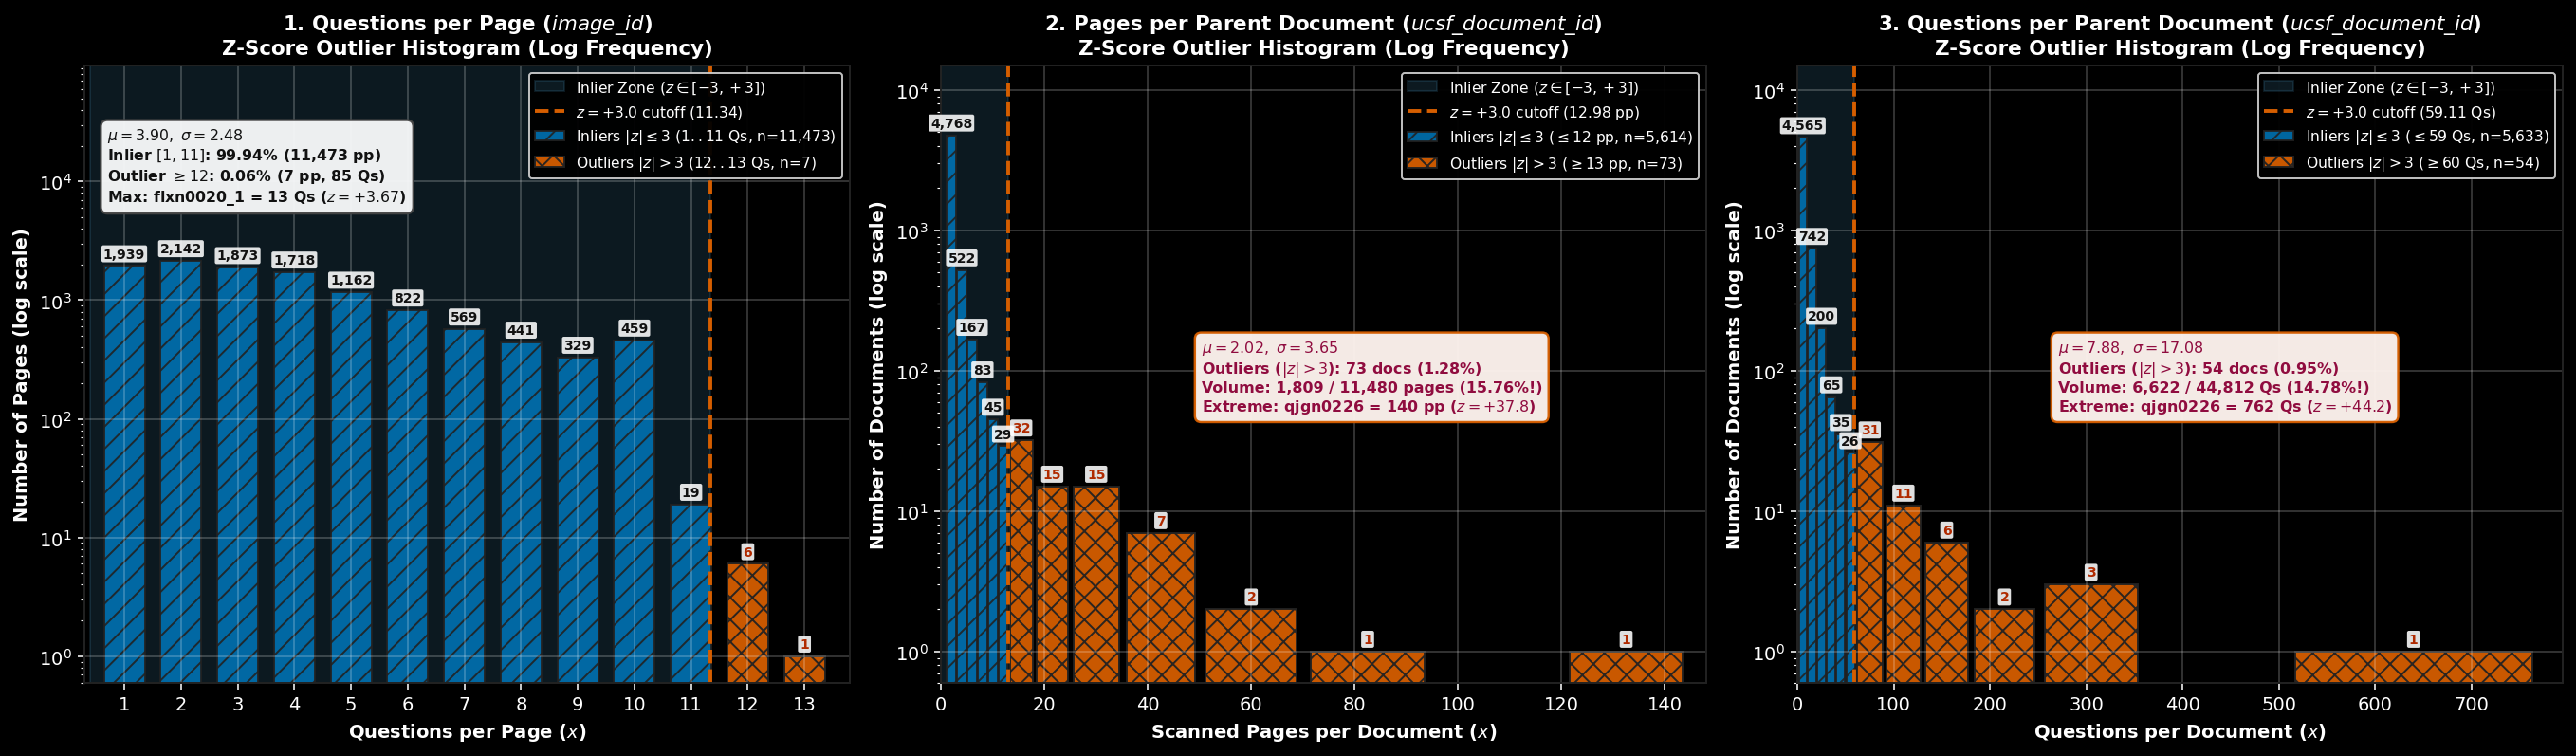

[saved] Z-score outlier histogram figure: DATA_PIPELINE/figures/stage1_zscore_outlier_histograms.png


#### Table 1.4b: All Page-Level Outliers ($|z| > 3$ on Questions per Page, $x \geq 12$)

,image_id,ucsf_document_id,split,Questions,OCR_Tokens,Resolution,Z_Score
0,flxn0020_1.png,flxn0020,validation,13,279,1692x2245,3.67
1,fzxw0023_1.png,fzxw0023,train,12,138,1692x2245,3.27
2,jkhn0226_1.png,jkhn0226,validation,12,85,1700x2200,3.27
3,nklg0227_3.png,nklg0227,train,12,177,1687x2183,3.27
4,ntbf0004_1.png,ntbf0004,train,12,162,1692x2245,3.27
5,ptkg0227_32.png,ptkg0227,validation,12,154,1696x2199,3.27
6,qqjw0228_10.png,qqjw0228,train,12,173,1770x2270,3.27


#### Table 1.4c: Top 15 Document-Level Mega-Outliers ($|z| > 3$ on Pages/Doc or Questions/Doc — Total 79 Outlier Docs)

,ucsf_document_id,Splits_Present,Train_Pages,Val_Pages,Total_Pages,Train_Qs,Val_Qs,Total_Qs,Mean_Qs_per_Page,Z_Pages,Z_Questions
0,qjgn0226,train | validation,133,7,140,716,46,762,5.44,37.76,44.16
1,xrcy0227,train | validation,79,1,80,343,2,345,4.31,21.34,19.74
2,hnnp0227,train | validation,54,6,60,304,33,337,5.62,15.87,19.27
3,kzng0227,train | validation,39,5,44,275,22,297,6.75,11.49,16.93
4,snyc0227,train | validation,34,4,38,208,12,220,5.79,9.85,12.42
5,jybx0223,train | validation,41,9,50,179,33,212,4.24,13.13,11.95
6,snbx0223,train | validation,25,20,45,89,86,175,3.89,11.76,9.79
7,pnbx0223,train,36,0,36,167,0,167,4.64,9.30,9.32
8,jnjm0223,train | validation,28,1,29,161,4,165,5.69,7.38,9.20
9,mnbx0223,train | validation,28,4,32,135,16,151,4.72,8.20,8.38


In [7]:
# 1.4a Z-Score Outlier Summary Table, 3-Panel Outlier Histograms & Top Outlier Inventory

s_doc_img = df_doc.groupby("image_id").size()
s_doc_pages = df_doc.groupby("ucsf_document_id")["image_id"].nunique()
s_doc_qs = df_doc.groupby("ucsf_document_id").size()
s_txt_img = df_txt.groupby("image_id").size()

def compute_z_stats(s: pd.Series, label: str, child_unit: str) -> dict:
    mu = float(s.mean())
    sd = float(s.std(ddof=1))
    z_lo = mu - 3.0 * sd
    z_hi = mu + 3.0 * sd
    z_scores = (s - mu) / sd
    is_out = z_scores.abs() > 3.0
    outliers = s[is_out]
    inliers = s[~is_out]
    return {
        "Distribution": label,
        "Total Entities (N)": len(s),
        "Mean (mu)": round(mu, 2),
        "Std (sigma)": round(sd, 2),
        "Z=[-3, +3] Raw Bound": f"[{z_lo:.2f}, {z_hi:.2f}]",
        "Inlier Integer Range": f"[1, {int(np.floor(z_hi))}]",
        "Inliers (|z|<=3)": f"{len(inliers):,} ({len(inliers)/len(s):.2%})",
        "Outliers (|z|>3)": f"{len(outliers):,} ({len(outliers)/len(s):.2%})",
        "Outlier Value Range": f"{int(outliers.min())}..{int(outliers.max())} (max z=+{z_scores.max():.2f})" if len(outliers) else "None",
        "Child Volume in Outliers": f"{int(outliers.sum()):,} / {int(s.sum()):,} {child_unit} ({outliers.sum()/s.sum():.2%})",
        "_mu": mu,
        "_sd": sd,
        "_z_lo": z_lo,
        "_z_hi": z_hi,
        "_outliers": outliers,
        "_z_max": float(z_scores.max()),
    }

st_img = compute_z_stats(s_doc_img, "1. DocVQA: Questions / Page (image_id)", "Qs")
st_pag = compute_z_stats(s_doc_pages, "2. DocVQA: Pages / Document (ucsf_document_id)", "Pages")
st_doc = compute_z_stats(s_doc_qs, "3. DocVQA: Questions / Document (ucsf_document_id)", "Qs")
st_txt = compute_z_stats(s_txt_img, "Ref. TextVQA: Questions / Scene Image (image_id)", "Qs")

summary_cols = [
    "Distribution", "Total Entities (N)", "Mean (mu)", "Std (sigma)",
    "Z=[-3, +3] Raw Bound", "Inlier Integer Range", "Inliers (|z|<=3)",
    "Outliers (|z|>3)", "Outlier Value Range", "Child Volume in Outliers"
]
display(Markdown("#### Table 1.4a: Z-Score Outlier Summary ($z \\in [-3, +3]$ Inliers vs. $|z| > 3$ Outliers)"))
display(pd.DataFrame([{k: d[k] for k in summary_cols} for d in (st_img, st_pag, st_doc, st_txt)]))

# --- 3-Panel Z-Score Outlier Histograms ---
fig, axes = plt.subplots(1, 3, figsize=(19.5, 5.8), dpi=140)

BOX_KW_LIGHT = dict(boxstyle="round,pad=0.45", fc="#F8F9FA", ec="#444444", lw=1.2, alpha=0.96)
BOX_KW_OUT   = dict(boxstyle="round,pad=0.42", fc="#FFF5F0", ec="#D55E00", lw=1.25, alpha=0.96)

# Panel 1: Questions per Page (image_id)
ax1 = axes[0]
vals_1 = np.arange(1, int(s_doc_img.max()) + 1)
counts_1 = np.array([(s_doc_img == v).sum() for v in vals_1])
z_hi_1 = st_img["_z_hi"]

inlier_mask_1 = vals_1 <= z_hi_1
outlier_mask_1 = vals_1 > z_hi_1

ax1.axvspan(0.4, z_hi_1, color=OKABE_ITO["sky"], alpha=0.14, zorder=0, label="Inlier Zone ($z \\in [-3, +3]$)")
ax1.bar(vals_1[inlier_mask_1], counts_1[inlier_mask_1], width=0.72,
        color=OKABE_ITO["blue"], edgecolor="#222222", hatch="//", alpha=0.9,
        label=f"Inliers $|z| \\leq 3$ ($1..11$ Qs, n={int(counts_1[inlier_mask_1].sum()):,})")
ax1.bar(vals_1[outlier_mask_1], counts_1[outlier_mask_1], width=0.72,
        color=OKABE_ITO["vermilion"], edgecolor="#222222", hatch="xx", alpha=0.95,
        label=f"Outliers $|z| > 3$ ($12..13$ Qs, n={int(counts_1[outlier_mask_1].sum()):,})")
ax1.axvline(z_hi_1, color=OKABE_ITO["vermilion"], linestyle="--", linewidth=2.0,
            label=f"$z = +3.0$ cutoff ({z_hi_1:.2f})")

ax1.set_yscale("log")
ax1.set_ylim(0.6, 95000)
ax1.set_xlim(0.3, 13.8)
ax1.set_xticks(vals_1)
ax1.set_title("1. Questions per Page ($image\\_id$)\nZ-Score Outlier Histogram (Log Frequency)", fontsize=11, fontweight="bold")
ax1.set_xlabel("Questions per Page ($x$)", fontweight="bold")
ax1.set_ylabel("Number of Pages (log scale)", fontweight="bold")
ax1.legend(loc="upper right", fontsize=8.0, framealpha=0.95)

for v, c in zip(vals_1, counts_1):
    if c > 0:
        col = "#B02A00" if v > z_hi_1 else "#111111"
        bg = dict(boxstyle="round,pad=0.14", fc="#FFFFFF", ec="none", alpha=0.88)
        ax1.annotate(f"{c:,}", xy=(v, c), xytext=(0, 3), textcoords="offset points",
                     ha="center", va="bottom", fontsize=7.2, fontweight="bold", color=col, bbox=bg)

ax1.annotate(
    f"$\\mu = {st_img['_mu']:.2f},\\ \\sigma = {st_img['_sd']:.2f}$\n"
    f"Inlier $[1, 11]$: 99.94% (11,473 pp)\n"
    f"Outlier $\\geq 12$: 0.06% (7 pp, 85 Qs)\n"
    f"Max: flxn0020_1 = 13 Qs ($z = +{st_img['_z_max']:.2f}$)",
    xy=(0.03, 0.78), xycoords="axes fraction",
    color="#111111", bbox=BOX_KW_LIGHT, fontsize=8.1, fontweight="bold"
)

# Panel 2: Pages per Parent Document (ucsf_document_id)
ax2 = axes[1]
z_hi_2 = st_pag["_z_hi"]
bins_2 = np.array([1, 3, 5, 7, 9, 11, 13, 18, 25, 35, 50, 70, 95, 120, 145], dtype=float)
counts_2, edges_2 = np.histogram(s_doc_pages, bins=bins_2)
centers_2 = 0.5 * (edges_2[:-1] + edges_2[1:])
widths_2 = (edges_2[1:] - edges_2[:-1]) * 0.88

inlier_bins_2 = edges_2[:-1] < z_hi_2
outlier_bins_2 = edges_2[:-1] >= z_hi_2

ax2.axvspan(0, z_hi_2, color=OKABE_ITO["sky"], alpha=0.14, zorder=0, label="Inlier Zone ($z \\in [-3, +3]$)")
ax2.bar(centers_2[inlier_bins_2], counts_2[inlier_bins_2], width=widths_2[inlier_bins_2],
        color=OKABE_ITO["blue"], edgecolor="#222222", hatch="//", alpha=0.9,
        label=f"Inliers $|z| \\leq 3$ ($\\leq 12$ pp, n=5,614)")
ax2.bar(centers_2[outlier_bins_2], counts_2[outlier_bins_2], width=widths_2[outlier_bins_2],
        color=OKABE_ITO["vermilion"], edgecolor="#222222", hatch="xx", alpha=0.95,
        label=f"Outliers $|z| > 3$ ($\\geq 13$ pp, n=73)")
ax2.axvline(z_hi_2, color=OKABE_ITO["vermilion"], linestyle="--", linewidth=2.0,
            label=f"$z = +3.0$ cutoff ({z_hi_2:.2f} pp)")

ax2.set_yscale("log")
ax2.set_ylim(0.6, 15000)
ax2.set_xlim(0, 148)
ax2.set_title("2. Pages per Parent Document ($ucsf\\_document\\_id$)\nZ-Score Outlier Histogram (Log Frequency)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Scanned Pages per Document ($x$)", fontweight="bold")
ax2.set_ylabel("Number of Documents (log scale)", fontweight="bold")
ax2.legend(loc="upper right", fontsize=8.0, framealpha=0.95)

for xc, c, is_out in zip(centers_2, counts_2, outlier_bins_2):
    if c > 0:
        col = "#B02A00" if is_out else "#111111"
        bg = dict(boxstyle="round,pad=0.14", fc="#FFFFFF", ec="none", alpha=0.88)
        ax2.annotate(f"{c:,}", xy=(xc, c), xytext=(0, 3), textcoords="offset points",
                     ha="center", va="bottom", fontsize=7.2, fontweight="bold", color=col, bbox=bg)

ax2.annotate(
    f"$\\mu = {st_pag['_mu']:.2f},\\ \\sigma = {st_pag['_sd']:.2f}$\n"
    f"Outliers ($|z|>3$): 73 docs (1.28%)\n"
    f"Volume: 1,809 / 11,480 pages (15.76%!)\n"
    f"Extreme: qjgn0226 = 140 pp ($z=+{st_pag['_z_max']:.1f}$)",
    xy=(0.34, 0.44), xycoords="axes fraction",
    color="#900C3F", bbox=BOX_KW_OUT, fontsize=8.2, fontweight="bold"
)

# Panel 3: Questions per Parent Document (ucsf_document_id)
ax3 = axes[2]
z_hi_3 = st_doc["_z_hi"]
bins_3 = np.array([1, 10, 20, 30, 40, 50, 60, 90, 130, 180, 250, 360, 500, 780], dtype=float)
counts_3, edges_3 = np.histogram(s_doc_qs, bins=bins_3)
centers_3 = 0.5 * (edges_3[:-1] + edges_3[1:])
widths_3 = (edges_3[1:] - edges_3[:-1]) * 0.88

inlier_bins_3 = edges_3[:-1] < z_hi_3
outlier_bins_3 = edges_3[:-1] >= z_hi_3

ax3.axvspan(0, z_hi_3, color=OKABE_ITO["sky"], alpha=0.14, zorder=0, label="Inlier Zone ($z \\in [-3, +3]$)")
ax3.bar(centers_3[inlier_bins_3], counts_3[inlier_bins_3], width=widths_3[inlier_bins_3],
        color=OKABE_ITO["blue"], edgecolor="#222222", hatch="//", alpha=0.9,
        label=f"Inliers $|z| \\leq 3$ ($\\leq 59$ Qs, n=5,633)")
ax3.bar(centers_3[outlier_bins_3], counts_3[outlier_bins_3], width=widths_3[outlier_bins_3],
        color=OKABE_ITO["vermilion"], edgecolor="#222222", hatch="xx", alpha=0.95,
        label=f"Outliers $|z| > 3$ ($\\geq 60$ Qs, n=54)")
ax3.axvline(z_hi_3, color=OKABE_ITO["vermilion"], linestyle="--", linewidth=2.0,
            label=f"$z = +3.0$ cutoff ({z_hi_3:.2f} Qs)")

ax3.set_yscale("log")
ax3.set_ylim(0.6, 15000)
ax3.set_xlim(0, 795)
ax3.set_title("3. Questions per Parent Document ($ucsf\\_document\\_id$)\nZ-Score Outlier Histogram (Log Frequency)", fontsize=11, fontweight="bold")
ax3.set_xlabel("Questions per Document ($x$)", fontweight="bold")
ax3.set_ylabel("Number of Documents (log scale)", fontweight="bold")
ax3.legend(loc="upper right", fontsize=8.0, framealpha=0.95)

for xc, c, is_out in zip(centers_3, counts_3, outlier_bins_3):
    if c > 0:
        col = "#B02A00" if is_out else "#111111"
        bg = dict(boxstyle="round,pad=0.14", fc="#FFFFFF", ec="none", alpha=0.88)
        ax3.annotate(f"{c:,}", xy=(xc, c), xytext=(0, 3), textcoords="offset points",
                     ha="center", va="bottom", fontsize=7.2, fontweight="bold", color=col, bbox=bg)

ax3.annotate(
    f"$\\mu = {st_doc['_mu']:.2f},\\ \\sigma = {st_doc['_sd']:.2f}$\n"
    f"Outliers ($|z|>3$): 54 docs (0.95%)\n"
    f"Volume: 6,622 / 44,812 Qs (14.78%!)\n"
    f"Extreme: qjgn0226 = 762 Qs ($z=+{st_doc['_z_max']:.1f}$)",
    xy=(0.34, 0.44), xycoords="axes fraction",
    color="#900C3F", bbox=BOX_KW_OUT, fontsize=8.2, fontweight="bold"
)

plt.tight_layout()
outlier_fig_path = REL_FIG_DIR / "stage1_zscore_outlier_histograms.png"
plt.savefig(outlier_fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"[saved] Z-score outlier histogram figure: {outlier_fig_path.as_posix()}")

# --- Detailed Inventory of Page-Level & Document-Level Outliers ---
page_agg = df_doc.groupby(["image_id", "ucsf_document_id", "split"]).agg(
    Questions=("question_id", "count"),
    OCR_Tokens=("ocr_token_count", "first"),
    Resolution=("image_width", lambda s: f"{s.iloc[0]}x{df_doc.loc[s.index[0], 'image_height']}"),
).reset_index()
page_agg["Z_Score"] = ((page_agg["Questions"] - st_img["_mu"]) / st_img["_sd"]).round(2)
page_outliers_df = page_agg[page_agg["Z_Score"].abs() > 3.0].sort_values("Questions", ascending=False).reset_index(drop=True)

display(Markdown("#### Table 1.4b: All Page-Level Outliers ($|z| > 3$ on Questions per Page, $x \\geq 12$)"))
display(page_outliers_df)

doc_agg = df_doc.groupby("ucsf_document_id").agg(
    Splits_Present=("split", lambda s: " | ".join(sorted(set(s)))),
    Train_Pages=("image_id", lambda s: s[df_doc.loc[s.index, "split"] == "train"].nunique()),
    Val_Pages=("image_id", lambda s: s[df_doc.loc[s.index, "split"] == "validation"].nunique()),
    Total_Pages=("image_id", "nunique"),
    Train_Qs=("split", lambda s: int((s == "train").sum())),
    Val_Qs=("split", lambda s: int((s == "validation").sum())),
    Total_Qs=("question_id", "count"),
    Mean_Qs_per_Page=("image_id", lambda s: round(len(s) / s.nunique(), 2)),
).reset_index()
doc_agg["Z_Pages"] = ((doc_agg["Total_Pages"] - st_pag["_mu"]) / st_pag["_sd"]).round(2)
doc_agg["Z_Questions"] = ((doc_agg["Total_Qs"] - st_doc["_mu"]) / st_doc["_sd"]).round(2)

doc_outliers_df = doc_agg[(doc_agg["Z_Pages"] > 3.0) | (doc_agg["Z_Questions"] > 3.0)].sort_values("Total_Qs", ascending=False).reset_index(drop=True)
display(Markdown(f"#### Table 1.4c: Top 15 Document-Level Mega-Outliers ($|z| > 3$ on Pages/Doc or Questions/Doc — Total {len(doc_outliers_df)} Outlier Docs)"))
display(doc_outliers_df.head(15))


### 1.4d Analytical Synthesis & Conclusion: What the $|z| > 3$ Outliers Reveal

Evaluating the three relational multiplicity distributions under the $z \in [-3, +3]$ inlier criterion uncovers three fundamental structural properties of the datasets:

1. **Bounded Page-Level Density vs. Unbounded Document-Level Heavy Tails:**
   - **Questions per Page (`image_id`)** is tightly bounded: the $z = +3.0$ threshold sits at **$11.34$ questions/page**, leaving $99.94\%$ of all DocVQA pages ($11,473 / 11,480$) within the normal inlier zone ($1..11$ questions). Only **7 pages ($0.06\%$)** exceed $z = +3$, peaking at $13$ questions (`flxn0020_1.png`, $z = +3.67$). In TextVQA, $100\%$ of images have $1$ or $2$ questions ($z \in [-1.17, +0.86]$), producing **zero outliers**.
   - Conversely, **Pages per Parent Document** ($z = +3.0$ at **$12.98$ pages**) and **Questions per Parent Document** ($z = +3.0$ at **$59.11$ questions**) exhibit extreme Pareto tails reaching **$140$ pages ($z = +37.76$)** and **$762$ questions ($z = +44.16$)** in a single parent document (`qjgn0226`).

2. **Disproportionate Volume Concentration Inside $|z| > 3$ Document Outliers:**
   - Although only **73 documents ($1.28\%$)** are page-count outliers ($\ge 13$ pages), they contain **1,809 pages — $15.76\%$ of all scanned pages in DocVQA**.
   - Similarly, although only **54 documents ($0.95\%$)** are question-count outliers ($\ge 60$ questions), they contain **6,622 questions — $14.78\%$ of the entire DocVQA benchmark ($44,812$ rows)**.

3. **Cross-Split Parent Document Bleed in the Official DocVQA Benchmark (`train | validation`):**
   - Inspecting `Splits_Present` in **Table 1.4c** reveals a critical finding: while the original DocVQA creators enforced zero page-image overlap (`image_id` overlap = $0$), they did **not** enforce `ucsf_document_id` disjointness across multi-page reports.
   - Consequently, **43 of the 54 question-outlier documents ($79.6\%$)** and **60 of the 73 page-outlier documents ($82.2\%$)** have pages present in **both** official `train` and official `validation` (for example, `qjgn0226` has $133$ pages / $716$ questions in `train` and $7$ pages / $46$ questions in `validation`).

4. **Actionable Engineering Rule for Phase B Internal Splitting (`train` $\rightarrow$ `internal_train` + `internal_dev`):**
   - When partitioning `train` into internal `train` (95%) and internal `dev` (5%, $\approx 1,973$ target questions) grouped by `ucsf_document_id`, the **54 mega-document outliers ($|z| > 3$)** cannot be assigned blindly.
   - If `qjgn0226` ($716$ train questions) were randomly sampled into `internal_dev`, a single document would consume **$36.3\%$ of the entire validation set**. Therefore, `GroupShuffleSplit` must be paired with a **group-size stratification / dominance cap** (e.g., ensuring no single `ucsf_document_id` in `internal_dev` exceeds $z = +3$, or stratifying group size buckets) so `internal_dev` remains diverse and representative.